In [1]:
"""
Logistic Regression in Code: Setosa vs. the Rest

@author:   Oscar Trevizo
@created:  November 16, 2026
@playlist: https://www.youtube.com/playlist?list=PLJgpRhj3_bvHVST9GVlT3_Su01bp_brLu
@data:     Iris flowers, sns.load_dataset('iris'): petal length and width

Setosa vs. the other two species: a train / test split, a logistic
regression model, and the decision boundary as a straight line, y = mx + b.
Built on camera in Google Colab.
"""

"\nLogistic Regression in Code: Setosa vs. the Rest\n\n@author:   Oscar Trevizo\n@created:  November 16, 2026\n@playlist: https://www.youtube.com/playlist?list=PLJgpRhj3_bvHVST9GVlT3_Su01bp_brLu\n@data:     Iris flowers, sns.load_dataset('iris'): petal length and width\n\nSetosa vs. the other two species: a train / test split, a logistic\nregression model, and the decision boundary as a straight line, y = mx + b.\nBuilt on camera in Google Colab.\n"

# Logistic Regression in Code — Part 1: The Iris Data

Iris flowers: can we tell setosa apart from the other species?

In [2]:
# --- Libraries: toolboxes other people wrote ---
import pandas as pd                # tables (DataFrames)
import numpy as np                 # math
import seaborn as sns              # charts, and a few sample datasets
import matplotlib.pyplot as plt    # basic plotting

# scikit-learn (written sklearn in code): Python's main machine-learning library.
# From two of its modules, we import two tools:
from sklearn.model_selection import train_test_split    # a FUNCTION: splits data into train / test
from sklearn.linear_model import LogisticRegression     # a CLASS: the blueprint for a logistic regression model

sns.set_style("darkgrid")

In [3]:
# --- Data: the Iris flowers, as a pandas DataFrame ---
iris_df = sns.load_dataset('iris')

In [4]:
iris_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [5]:
iris_df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [6]:
iris_df['species'].value_counts()

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

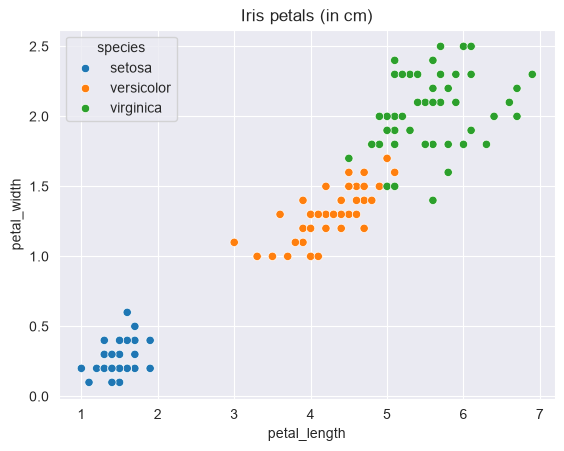

In [7]:
sns.scatterplot(data=iris_df, x='petal_length', y='petal_width', hue='species')
plt.title('Iris petals (in cm)')
plt.show()

# Part 1b: Setosa vs. the Rest

Two classes, a train / test split, and a first model.

In [8]:
# New column: 'setosa' for setosa flowers, 'other' for the other two species
iris_df['setosa_or_other'] = np.where(iris_df['species'] == 'setosa', 'setosa', 'other')

iris_df['setosa_or_other'].value_counts()

setosa_or_other
other     100
setosa     50
Name: count, dtype: int64

## Train / test split

In [9]:
# X = predictors (the inputs we learn from): petal length and petal width
# y = target (the answer we want to predict): setosa or other
X = iris_df[['petal_length', 'petal_width']]
y = iris_df['setosa_or_other']

# Shuffle the 150 flowers, then split them into training and test sets.
# train_test_split returns FOUR pieces, named on the left of the = sign:
#   x_train, y_train -> 120 flowers the model learns from (inputs and answers)
#   x_test,  y_test  ->  30 flowers held back to check the model (inputs and answers)
x_train, x_test, y_train, y_test = train_test_split(
    X,                  # predictors
    y,                  # target
    test_size=0.2,      # 20% of the flowers go to the test set
    stratify=y,         # same share of setosa in both sets
    random_state=40,    # same shuffle every run
)

In [10]:
x_train.shape, x_test.shape

((120, 2), (30, 2))

## Fit the model

In [11]:
setosa_lgr = LogisticRegression()
setosa_lgr.fit(x_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [12]:
setosa_lgr.intercept_

array([7.44745776])

In [13]:
setosa_lgr.coef_

array([[-2.45345337, -1.01748884]])

In [14]:
setosa_lgr.score(x_test, y_test)

1.0

In [15]:
y_pred = setosa_lgr.predict(x_test)
y_pred

array(['other', 'setosa', 'setosa', 'setosa', 'setosa', 'other', 'setosa',
       'other', 'other', 'setosa', 'other', 'other', 'other', 'other',
       'setosa', 'other', 'other', 'other', 'other', 'other', 'setosa',
       'other', 'other', 'setosa', 'other', 'other', 'setosa', 'other',
       'other', 'other'], dtype=object)

In [16]:
# Actual answers next to the model's predictions
compare_df = pd.DataFrame({'actual': y_test, 'predicted': y_pred})
compare_df.head(10)

,actual,predicted
62,other,other
42,setosa,setosa
16,setosa,setosa
4,setosa,setosa
19,setosa,setosa
100,other,other
24,setosa,setosa
121,other,other
124,other,other
37,setosa,setosa


## The boundary line: y = mx + b

At p = 0.5, the logit is 0: β0 + β1·length + β2·width = 0.
Solved for width: width = m·length + b, with m = −β1/β2 and b = −β0/β2.

In [17]:
# The model's three numbers (from video 1b)
beta0 = setosa_lgr.intercept_[0]       # intercept
beta1, beta2 = setosa_lgr.coef_[0]     # coefficient for petal length, then petal width

print(f"beta0 = {beta0:.2f}   beta1 = {beta1:.2f}   beta2 = {beta2:.2f}")

beta0 = 7.45   beta1 = -2.45   beta2 = -1.02


In [18]:
# The boundary line: width = slope_m * length + intercept_b
slope_m = -beta1 / beta2         # slope of the line
intercept_b = -beta0 / beta2     # the LINE's intercept (not the model's intercept_)

print(f"m = {slope_m:.2f}   b = {intercept_b:.2f}")

m = -2.41   b = 7.32


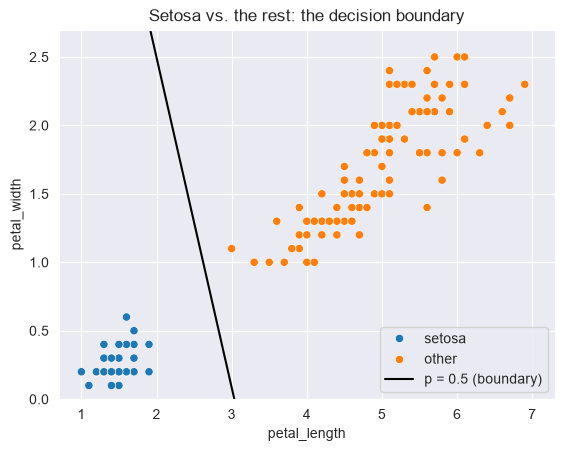

In [19]:
# 100 petal lengths from 1 to 7 cm, and the width on the line for each
length_grid = np.linspace(1, 7, 100)
width_on_line = slope_m * length_grid + intercept_b

# All 150 flowers, plus the line
sns.scatterplot(data=iris_df, x='petal_length', y='petal_width', hue='setosa_or_other')
plt.plot(length_grid, width_on_line, color='black', label='p = 0.5 (boundary)')
plt.ylim(0, 2.7)       # keep the view on the flowers; the line keeps going
plt.title('Setosa vs. the rest: the decision boundary')
plt.legend()
plt.show()